<a href="https://colab.research.google.com/github/syifaymd/Tugas-Kelompok-7/blob/main/Pemodelan_Padi_Sulawesi_Rinci.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Peramalan Produksi Padi Sulawesi
## Notebook Google Colab • Tahapan pemodelan deret waktu

**Y = produksi; X1 = luas panen; X2 = curah hujan.** Analisis dilakukan **terpisah untuk enam provinsi**, bukan menggabungkan deret provinsi menjadi satu deret. Urutan mengikuti PDF *Tahapan pemodelan data deret waktu*: Business Understanding → Data Understanding → Data Preparation → Modeling → Evaluation → Forecasting & Monitoring.

**Cara menggunakan:** unggah notebook ini melalui Google Colab → File → Upload notebook. Jalankan sel berurutan. Pada sel unggah data, pilih Excel asli. Semua tabel dan gambar disimpan dalam folder `hasil_padi_sulawesi`; sel terakhir menyediakan ZIP hasil. CPU cukup. Pencarian model dapat memakan waktu karena setiap kandidat dilatih pada dua lipatan berurutan untuk setiap provinsi.

**Data sumber yang diperiksa:** Sheet1; kolom `Provinsi, Tahun, Bulan, Y, X1, X2`; 104 observasi per provinsi Sulawesi, Januari 2018–Agustus 2026. Tidak ditemukan nilai kosong pada enam provinsi dalam file yang diberikan. Satuan tidak tertulis di header, sehingga **konfirmasikan satuan produksi, luas panen, dan hujan sebelum menulis laporan**. Nilai 2026 diperlakukan sebagai observasi sesuai file, bukan diverifikasi sebagai realisasi resmi.

## 1. Business Understanding
Tujuan: memprediksi produksi padi bulanan 12 bulan mendatang untuk Sulawesi Utara, Sulawesi Tengah, Sulawesi Selatan, Sulawesi Tenggara, Gorontalo, dan Sulawesi Barat. Hasil mendukung perencanaan produksi, tetapi hubungan X dengan Y di sini bersifat prediktif, bukan bukti kausal.

Model yang digunakan:
1. **Seasonal naïve**: nilai bulan yang sama tahun sebelumnya sebagai baseline.
2. **SARIMA**: dinamika produksi dan musiman tahunan tanpa X.
3. **SARIMAX**: regresi produksi terhadap X1 dan X2 dengan galat SARIMA.

PDF menyajikan ragam model, bukan kewajiban menggunakan semuanya. SARIMAX dipilih karena data bulanan memiliki dua prediktor eksternal. Model RF/hybrid dan deep learning tidak menjadi bagian notebook ini.

**Protokol keputusan:** sisihkan 12 bulan terakhir sebagai test; pilih kandidat dan keluarga model menggunakan RMSE validasi expanding window pada data sebelum test. Test dipakai sekali untuk audit, bukan untuk mengulang pencarian parameter. Setelah audit, orde terpilih diestimasi ulang menggunakan seluruh sejarah untuk ramalan ke depan.

In [1]:
# Instal dependensi di Google Colab. Tidak mengubah file data sumber.
import sys, subprocess
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                       'numpy', 'pandas', 'openpyxl', 'matplotlib',
                       'scipy', 'statsmodels>=0.14,<0.15', 'scikit-learn'])

0

In [2]:
from pathlib import Path
from itertools import product
import json, shutil, warnings, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import statsmodels
from IPython.display import display
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

PROVINSI = ['SULAWESI UTARA','SULAWESI TENGAH','SULAWESI SELATAN',
            'SULAWESI TENGGARA','GORONTALO','SULAWESI BARAT']
S, H, TEST_SIZE = 12, 12, 12
N_FOLDS, CV_H = 2, 12
ALPHA = 0.05
MAXITER = 200
# None: unggah melalui dialog Colab. Untuk lokal, isi path Excel.
DATA_PATH = None
# CSV opsional: Provinsi,Tanggal,X1,X2 untuk 12 bulan setelah data terakhir.
# Jika None, X masa depan memakai seasonal naïve yang transparan.
FUTURE_X_PATH = None
OUT = Path('hasil_padi_sulawesi'); OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (11,4), 'axes.grid': True,
                     'grid.alpha': 0.25, 'font.size': 10})
VERSI = {'python':platform.python_version(), 'pandas':pd.__version__,
         'numpy':np.__version__, 'statsmodels':statsmodels.__version__}
print(VERSI)

def simpan_gambar(nama):
    plt.tight_layout()
    plt.savefig(OUT / f'{nama}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close('all')

def simpan_tabel(df, nama, index=False):
    df.to_csv(OUT / f'{nama}.csv', index=index, encoding='utf-8-sig')

{'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6', 'statsmodels': '0.14.6'}


## 2. Data Understanding
### 2.1 Membaca, memeriksa, dan menyaring data
Kode menggunakan nama kolom persis seperti file Anda. Bulan berbahasa Indonesia dikonversi menjadi tanggal awal bulan. Duplikasi provinsi-bulan, nilai negatif, dan bulan tidak dikenal menghentikan proses agar masalah tidak tersembunyi. Data provinsi lain tidak dimodelkan.

In [3]:
if DATA_PATH is None:
    from google.colab import files
    unggahan = files.upload()
    excel = [k for k in unggahan if k.lower().endswith('.xlsx')]
    if len(excel) != 1:
        raise ValueError('Unggah tepat satu file Excel data padi.')
    DATA_PATH = excel[0]

raw = pd.read_excel(DATA_PATH, sheet_name='Sheet1')
raw.columns = raw.columns.str.strip()
required = {'Provinsi','Tahun','Bulan','Y','X1','X2'}
if not required.issubset(raw.columns):
    raise ValueError(f'Kolom belum lengkap: {required - set(raw.columns)}')
raw['Provinsi'] = raw['Provinsi'].astype(str).str.strip().str.upper()
data = raw.loc[raw.Provinsi.isin(PROVINSI)].copy()
if set(data.Provinsi) != set(PROVINSI):
    raise ValueError('Ada provinsi Sulawesi yang tidak ditemukan.')
bulan = {b:i+1 for i,b in enumerate(['januari','februari','maret','april',
          'mei','juni','juli','agustus','september','oktober','november','desember'])}
bulan['nopember'] = 11  # Ejaan November pada Excel sumber.
data['Nomor_bulan'] = data.Bulan.astype(str).str.strip().str.lower().map(bulan)
if data.Nomor_bulan.isna().any():
    raise ValueError('Nama bulan tidak dikenali.')
data['Tanggal'] = pd.to_datetime(dict(year=data.Tahun,month=data.Nomor_bulan,day=1))
if data.duplicated(['Provinsi','Tanggal']).any():
    raise ValueError('Ada duplikasi provinsi-bulan. Periksa sumber, jangan langsung dijumlahkan.')
for c in ['Y','X1','X2']:
    data[c] = pd.to_numeric(data[c], errors='raise')
    if (data[c] < 0).any() or np.isinf(data[c]).any():
        raise ValueError(f'Nilai negatif/tidak terbatas ditemukan pada {c}.')
data = data.sort_values(['Provinsi','Tanggal'])
seri = {p:g.set_index('Tanggal')[['Y','X1','X2']].asfreq('MS')
        for p,g in data.groupby('Provinsi')}
audit = pd.DataFrame([{'Provinsi':p,'Awal':g.index.min(),'Akhir':g.index.max(),
                      'N_bulan':len(g), **{f'Missing_{c}':g[c].isna().sum() for c in g}}
                     for p,g in seri.items()])
display(audit); display(data.head()); display(data[['Y','X1','X2']].describe())
simpan_tabel(audit,'01_audit_data')
simpan_tabel(data,'02_data_sulawesi')

Saving Data_Padi.xlsx to Data_Padi.xlsx


,Provinsi,Awal,Akhir,N_bulan,Missing_Y,Missing_X1,Missing_X2
0,GORONTALO,2018-01-01,2026-08-01,104,0,0,0
1,SULAWESI BARAT,2018-01-01,2026-08-01,104,0,0,0
2,SULAWESI SELATAN,2018-01-01,2026-08-01,104,0,0,0
3,SULAWESI TENGAH,2018-01-01,2026-08-01,104,0,0,0
4,SULAWESI TENGGARA,2018-01-01,2026-08-01,104,0,0,0
5,SULAWESI UTARA,2018-01-01,2026-08-01,104,0,0,0


,Provinsi,Tahun,Bulan,Y,X1,X2,Nomor_bulan,Tanggal
2912,GORONTALO,2018,Januari,42111.32,8509.17,173.794213,1,2018-01-01
2913,GORONTALO,2018,Februari,33868.85,6879.34,118.369291,2,2018-02-01
2914,GORONTALO,2018,Maret,18530.15,3791.26,147.675398,3,2018-03-01
2915,GORONTALO,2018,April,21931.64,4358.70,156.255446,4,2018-04-01
2916,GORONTALO,2018,Mei,17681.66,3681.45,166.326695,5,2018-05-01


,Y,X1,X2
count,6.240000e+02,624.000000,624.000000
mean,1.028255e+05,20953.635842,207.719052
std,1.934021e+05,38047.488987,91.835381
min,2.264040e+03,490.580000,4.587938
25%,2.072331e+04,4544.980000,143.702853
50%,3.342994e+04,7119.660000,208.179176
75%,7.512803e+04,16483.095661,269.813094
max,1.163518e+06,219866.880000,515.516143


### 2.2 Grafik, tren, musiman, hubungan antarvariabel
Grafik seluruh sejarah memberikan gambaran deskriptif. Dekomposisi STL, korelasi, deteksi kandidat outlier, dan identifikasi model berikut hanya memakai data latih. Korelasi tinggi Y–X1 perlu dibaca hati-hati: produksi secara substantif berkaitan erat dengan luas panen. Ketersediaan luas panen pada waktu penerbitan ramalan harus diperhatikan.

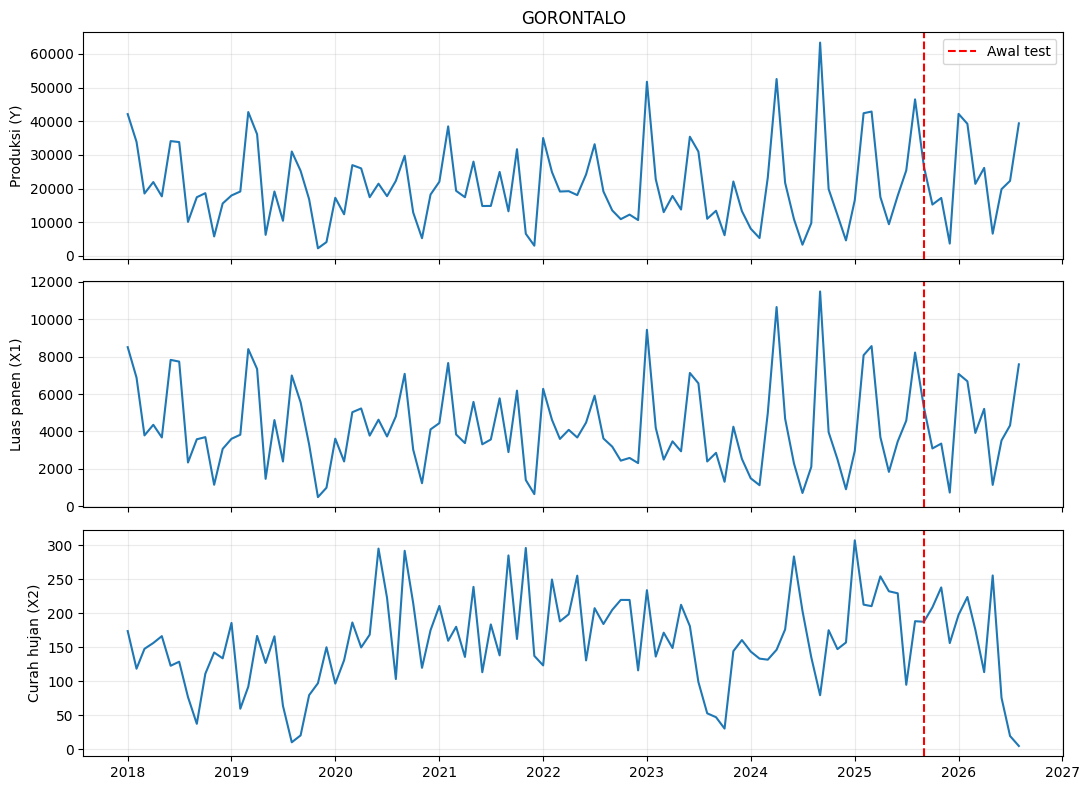

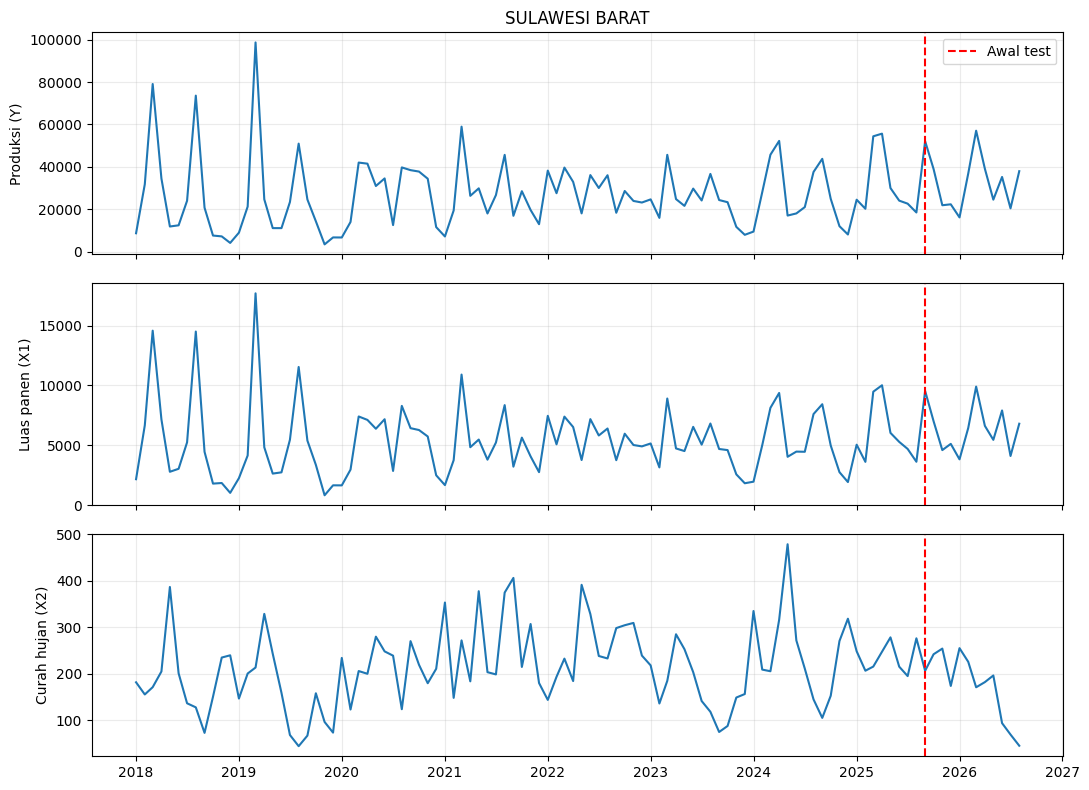

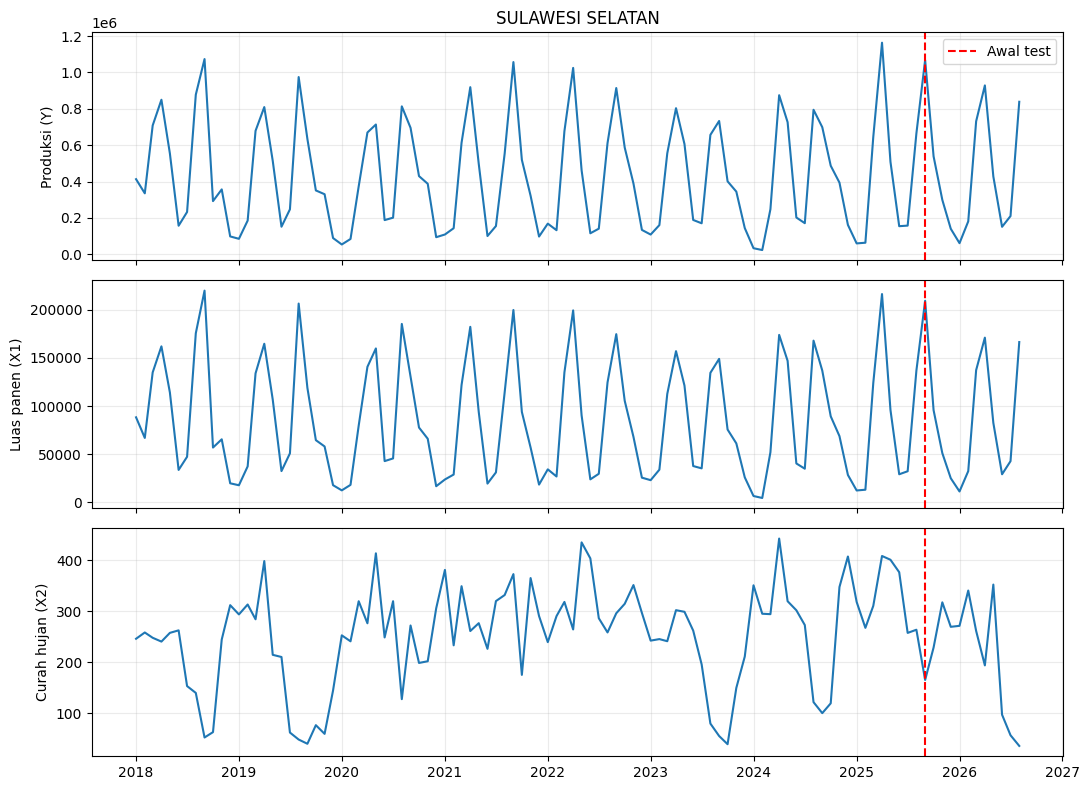

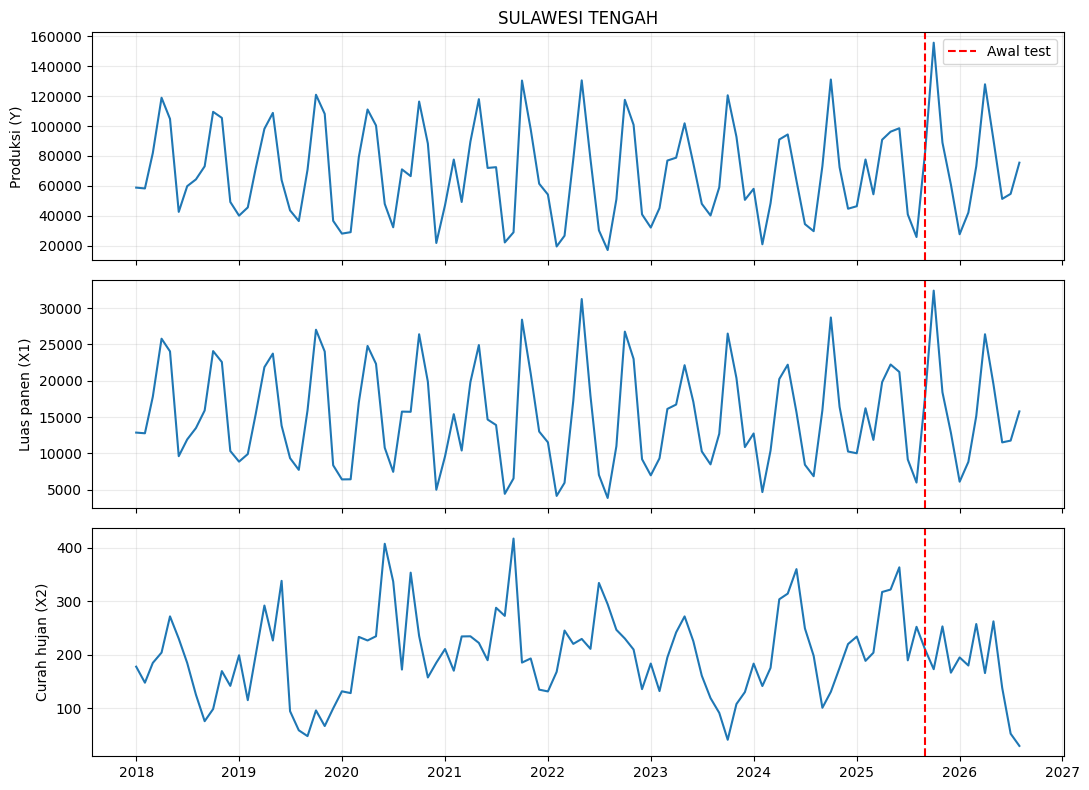

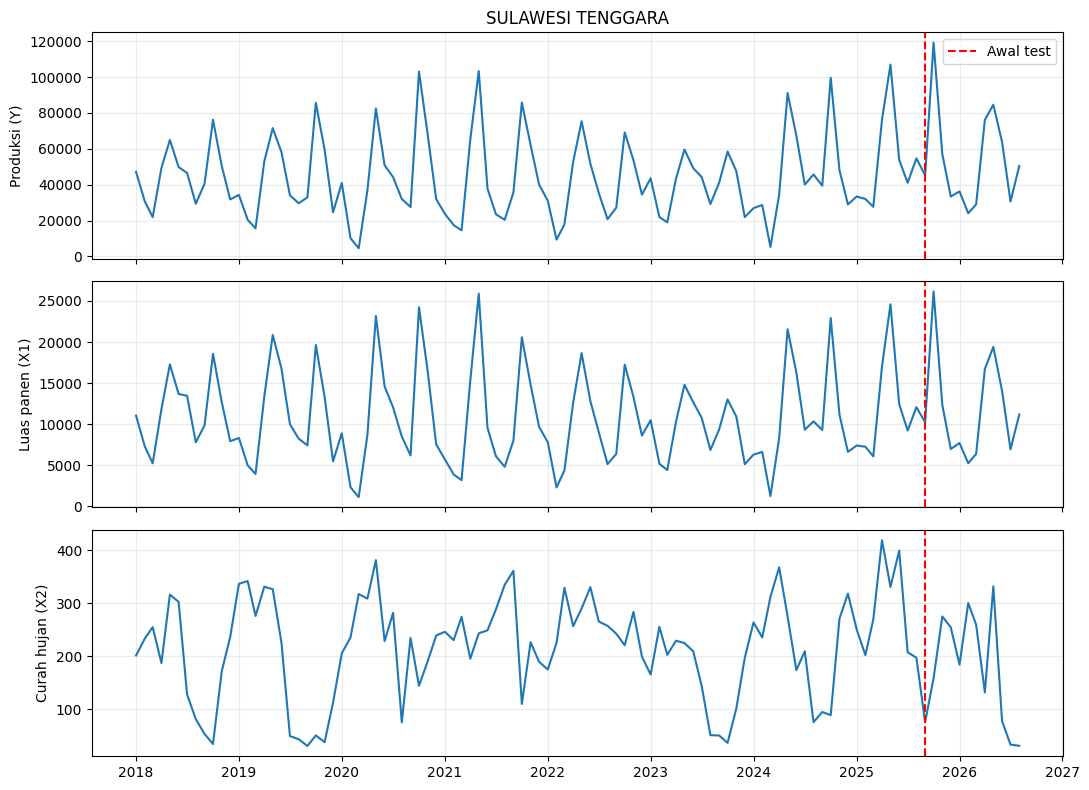

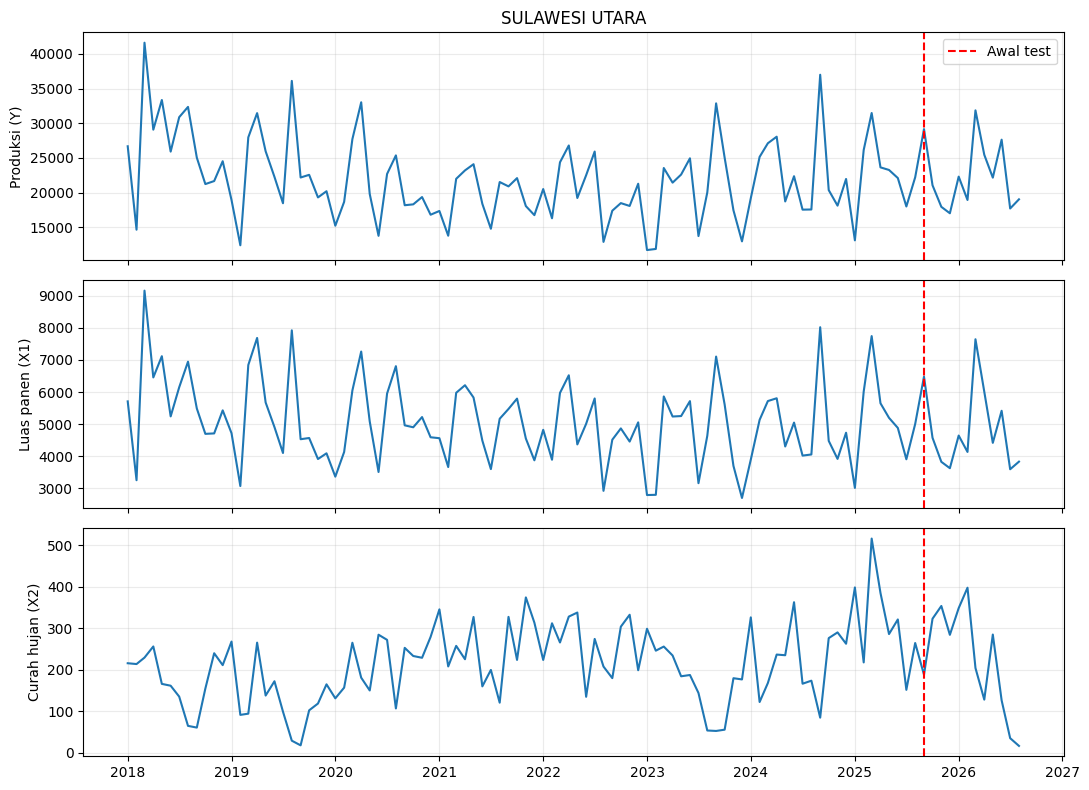

In [4]:
for p,g in seri.items():
    fig, axes = plt.subplots(3,1,figsize=(11,8),sharex=True)
    for ax,c,label in zip(axes,['Y','X1','X2'],['Produksi (Y)','Luas panen (X1)','Curah hujan (X2)']):
        ax.plot(g.index,g[c]); ax.set_ylabel(label)
        ax.axvline(g.index[-TEST_SIZE],color='red',ls='--',label='Awal test')
    axes[0].set_title(p); axes[0].legend()
    simpan_gambar(f'EDA_{p}')

## 3. Data Preparation
### 3.1 Split kronologis dan penanganan missing/outlier
Dengan data asli: **train Januari 2018–Agustus 2025 (92 bulan)**; **test September 2025–Agustus 2026 (12 bulan)**. Di dalam train, validasi memakai dua origin: pelatihan 68 bulan → validasi 12 bulan, kemudian pelatihan 80 bulan → validasi 12 bulan. Tidak ada random split.

Default menghentikan analisis jika data tidak lengkap. Ini disengaja agar Y test tidak diisi dengan angka buatan. Jika perlu imputasi, lakukan terpisah dalam setiap fold dan hanya gunakan informasi yang tersedia pada origin. Jangan menginterpolasi seluruh data sebelum split. Nilai ekstrem hanya ditandai, tidak otomatis dihapus karena dapat mewakili puncak panen yang nyata.

,Provinsi,n_train,n_test,train_akhir,test_awal,test_akhir
0,GORONTALO,92,12,2025-08-01,2025-09-01,2026-08-01
1,SULAWESI BARAT,92,12,2025-08-01,2025-09-01,2026-08-01
2,SULAWESI SELATAN,92,12,2025-08-01,2025-09-01,2026-08-01
3,SULAWESI TENGAH,92,12,2025-08-01,2025-09-01,2026-08-01
4,SULAWESI TENGGARA,92,12,2025-08-01,2025-09-01,2026-08-01
5,SULAWESI UTARA,92,12,2025-08-01,2025-09-01,2026-08-01


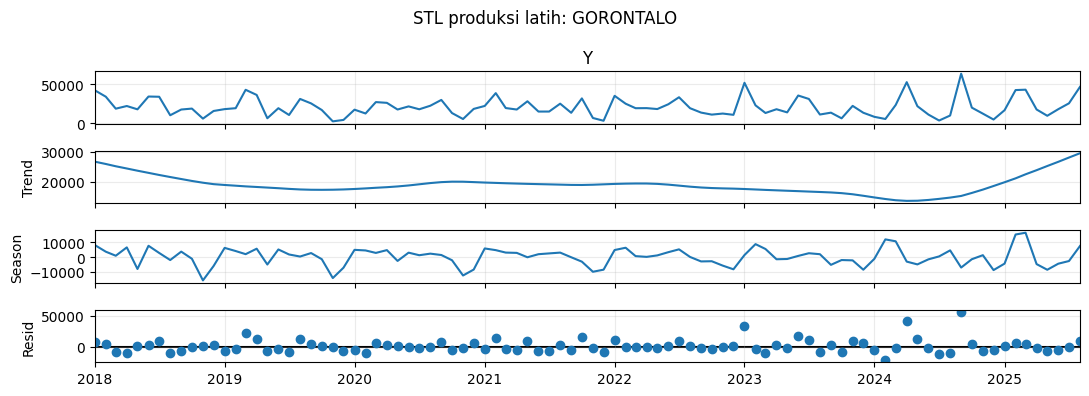

GORONTALO korelasi data latih


,Y,X1,X2
Y,1.000000,0.987632,0.005224
X1,0.987632,1.000000,-0.006585
X2,0.005224,-0.006585,1.000000


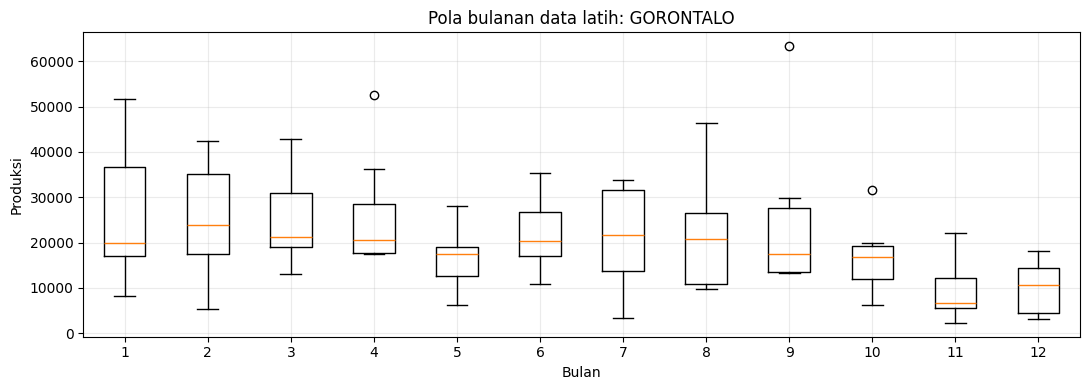

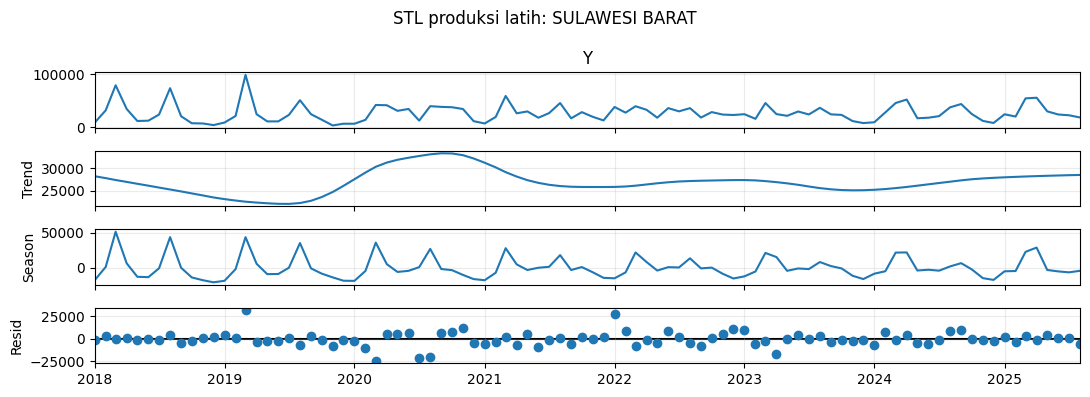

SULAWESI BARAT korelasi data latih


,Y,X1,X2
Y,1.000000,0.989612,-0.068963
X1,0.989612,1.000000,-0.099051
X2,-0.068963,-0.099051,1.000000


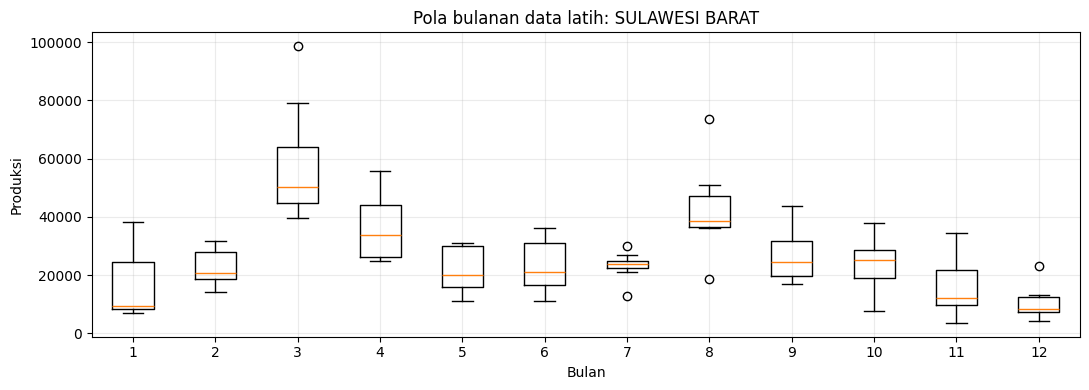

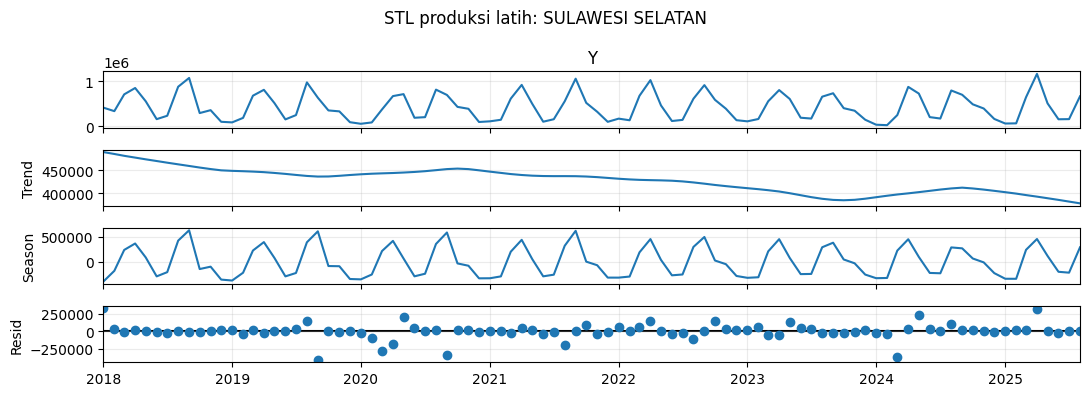

SULAWESI SELATAN korelasi data latih


,Y,X1,X2
Y,1.000000,0.995157,-0.092416
X1,0.995157,1.000000,-0.102424
X2,-0.092416,-0.102424,1.000000


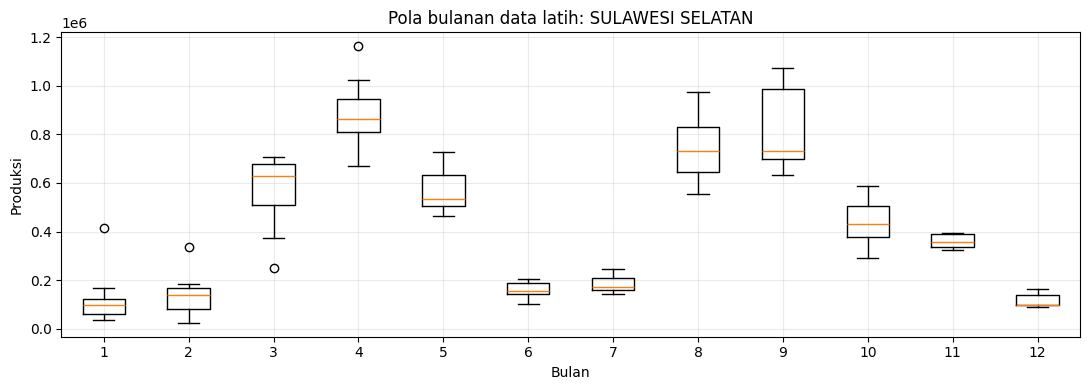

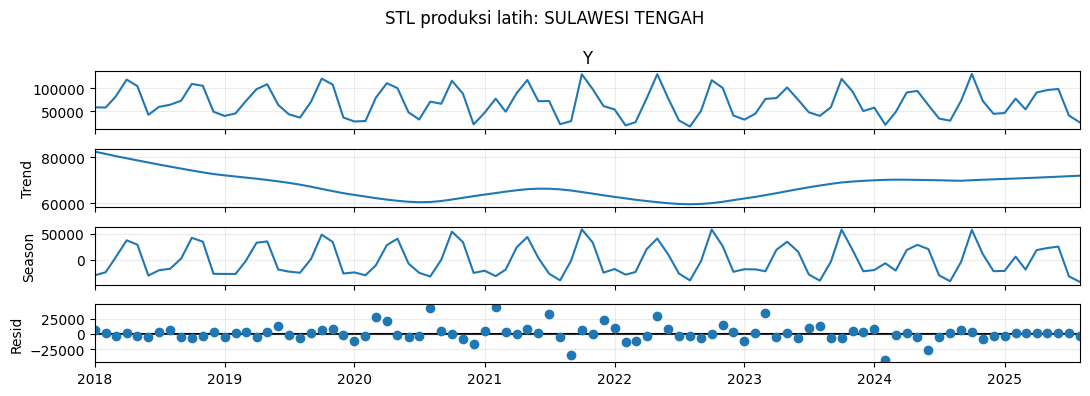

SULAWESI TENGAH korelasi data latih


,Y,X1,X2
Y,1.000000,0.995591,-0.018814
X1,0.995591,1.000000,0.004415
X2,-0.018814,0.004415,1.000000


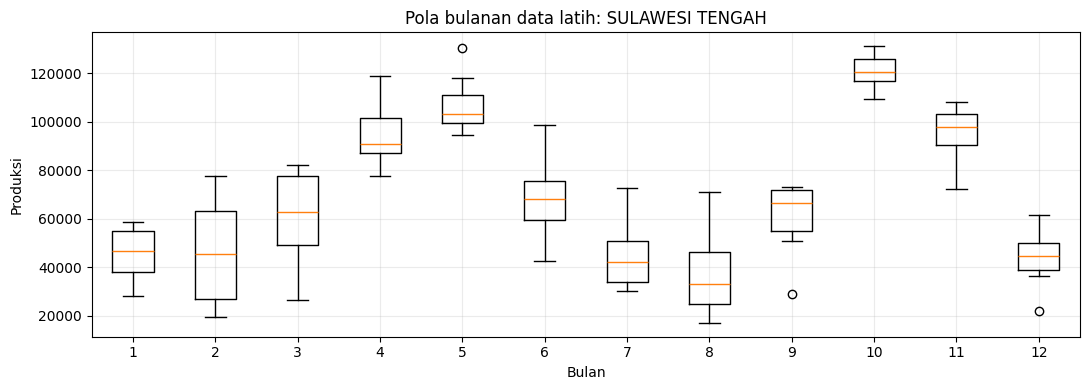

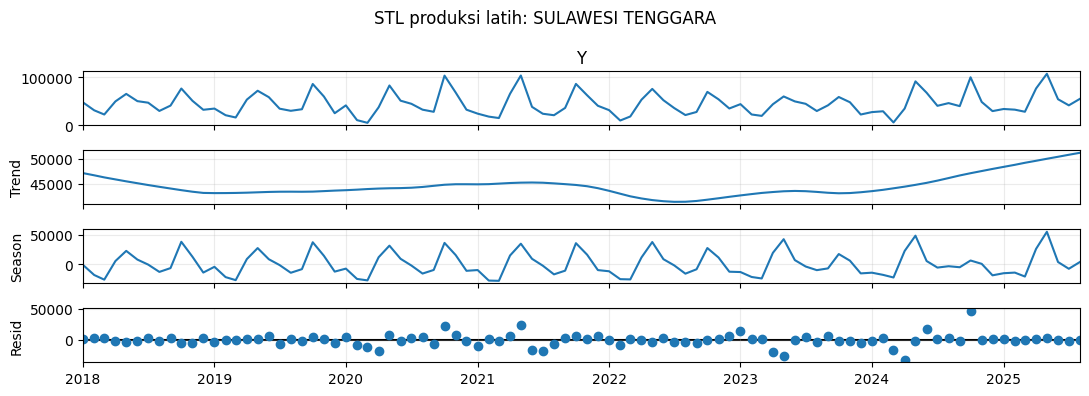

SULAWESI TENGGARA korelasi data latih


,Y,X1,X2
Y,1.000000,0.987198,-0.092629
X1,0.987198,1.000000,-0.067682
X2,-0.092629,-0.067682,1.000000


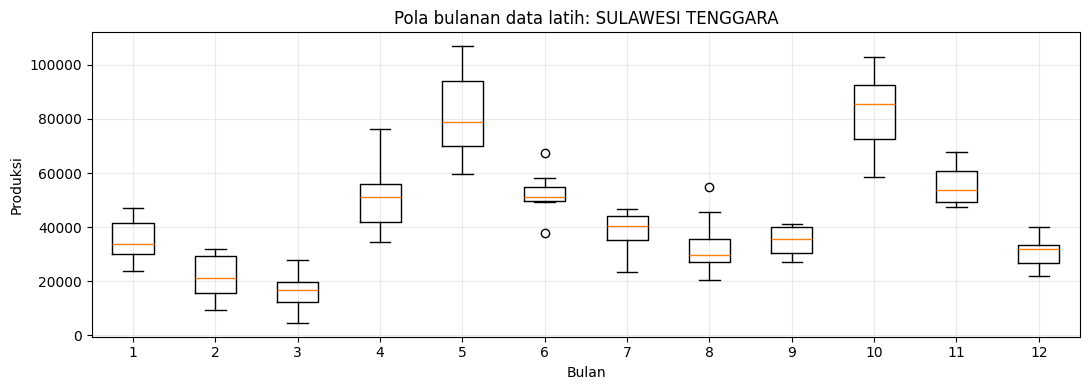

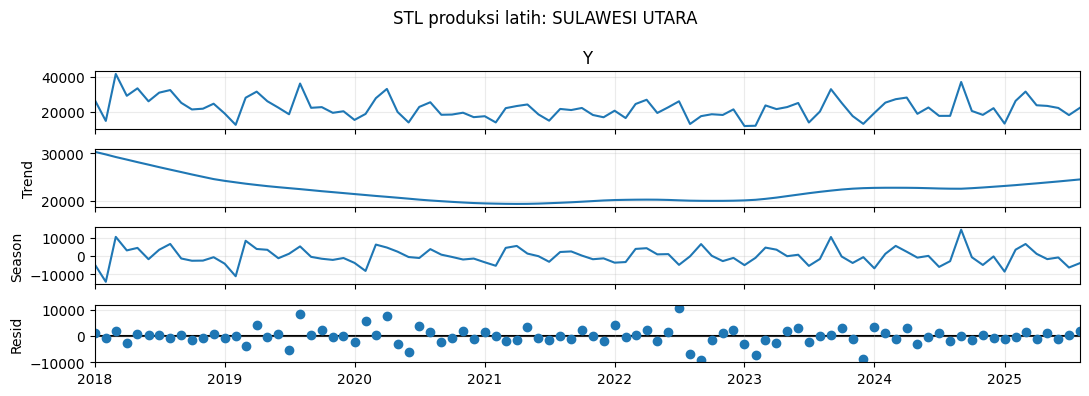

SULAWESI UTARA korelasi data latih


,Y,X1,X2
Y,1.000000,0.949427,-0.194183
X1,0.949427,1.000000,-0.079697
X2,-0.194183,-0.079697,1.000000


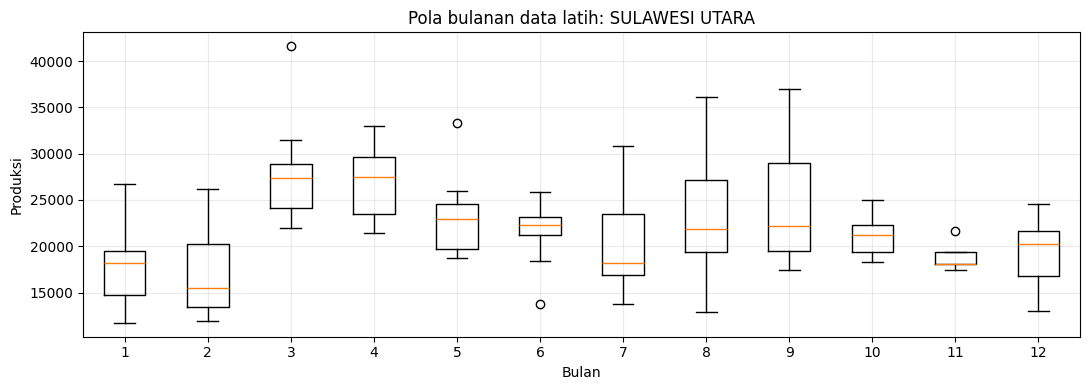

,Provinsi,Tanggal,Y,robust_z_residu_STL
0,GORONTALO,2023-01-01,51713.96,4.391881
1,GORONTALO,2024-04-01,52527.81,5.612999
2,GORONTALO,2024-09-01,63337.53,7.355316
3,SULAWESI BARAT,2019-03-01,98640.98,6.381169
4,SULAWESI BARAT,2020-03-01,42067.03,-4.623022
5,SULAWESI BARAT,2020-07-01,12640.95,-3.957475
6,SULAWESI BARAT,2020-08-01,39788.84,-3.838095
7,SULAWESI BARAT,2022-01-01,38290.44,5.491629
8,SULAWESI SELATAN,2018-01-01,413279.95,9.956318
9,SULAWESI SELATAN,2019-08-01,974677.51,4.570294


In [5]:
train, test = {}, {}
split_rows = []
for p,g in seri.items():
    if g.isna().any().any():
        raise ValueError(f'{p}: ada bulan/nilai hilang. Periksa sumber sebelum pemodelan.')
    if len(g) - TEST_SIZE - N_FOLDS*CV_H < 48:
        raise ValueError(f'{p}: data terlalu pendek untuk konfigurasi validasi ini.')
    train[p], test[p] = g.iloc[:-TEST_SIZE].copy(), g.iloc[-TEST_SIZE:].copy()
    split_rows.append({'Provinsi':p,'n_train':len(train[p]),'n_test':len(test[p]),
                      'train_akhir':train[p].index[-1],'test_awal':test[p].index[0],
                      'test_akhir':test[p].index[-1]})
display(pd.DataFrame(split_rows))
simpan_tabel(pd.DataFrame(split_rows),'03_split')

outliers = []
for p,g in train.items():
    stl = STL(g.Y,period=S,robust=True).fit()
    stl.plot(); plt.suptitle(f'STL produksi latih: {p}')
    simpan_gambar(f'STL_{p}')
    resid = stl.resid
    mad = np.median(np.abs(resid - np.median(resid)))
    score = 0.6745*(resid - np.median(resid))/mad if mad > 0 else resid*0
    for t in score.index[np.abs(score)>3.5]:
        outliers.append({'Provinsi':p,'Tanggal':t,'Y':g.loc[t,'Y'],
                         'robust_z_residu_STL':score.loc[t]})
    print(p, 'korelasi data latih'); display(g.corr())
    simpan_tabel(g.corr(),f'korelasi_{p}',index=True)
    fig,ax=plt.subplots()
    ax.boxplot([g.Y[g.index.month==m] for m in range(1,13)])
    ax.set(xlabel='Bulan',ylabel='Produksi',title=f'Pola bulanan data latih: {p}')
    simpan_gambar(f'kalender_musim_{p}')
outlier_table = pd.DataFrame(outliers,columns=['Provinsi','Tanggal','Y','robust_z_residu_STL'])
display(outlier_table); simpan_tabel(outlier_table,'04_kandidat_outlier')

### 3.2 Transformasi, stasioneritas, differencing, ACF/PACF
ADF: H₀ = memiliki akar unit; p < 0,05 mendukung penolakan akar unit. KPSS dengan konstanta: H₀ = stasioner pada level; p < 0,05 menunjukkan bukti menolak stasioneritas. Keduanya bukan bukti tunggal penentuan orde dan bukan uji akar unit musiman khusus.

Tabel memeriksa Y, X1, X2 pada bentuk asli, log1p, beda pertama, beda musiman 12, dan kombinasi keduanya. Log1p hanya eksplorasi; **pemodelan default tetap pada skala asli** agar estimasi rerata dan interval kembali ke satuan Y tanpa persoalan bias inverse log. Jika memilih log pada pengembangan lanjutan, lakukan pilihan berdasarkan train/validasi dan tangani bias transformasi balik.

Model menerima data level yang diskalakan, bukan data yang telah di-difference manual. Parameter `d` dan `D` pada SARIMAX menangani integrasi, sehingga tidak terjadi double differencing. Skala Y dibagi simpangan baku train dan X distandardisasi menggunakan statistik train **di setiap fold**. ACF/PACF membantu membaca pola, sementara orde final dipilih melalui validasi.

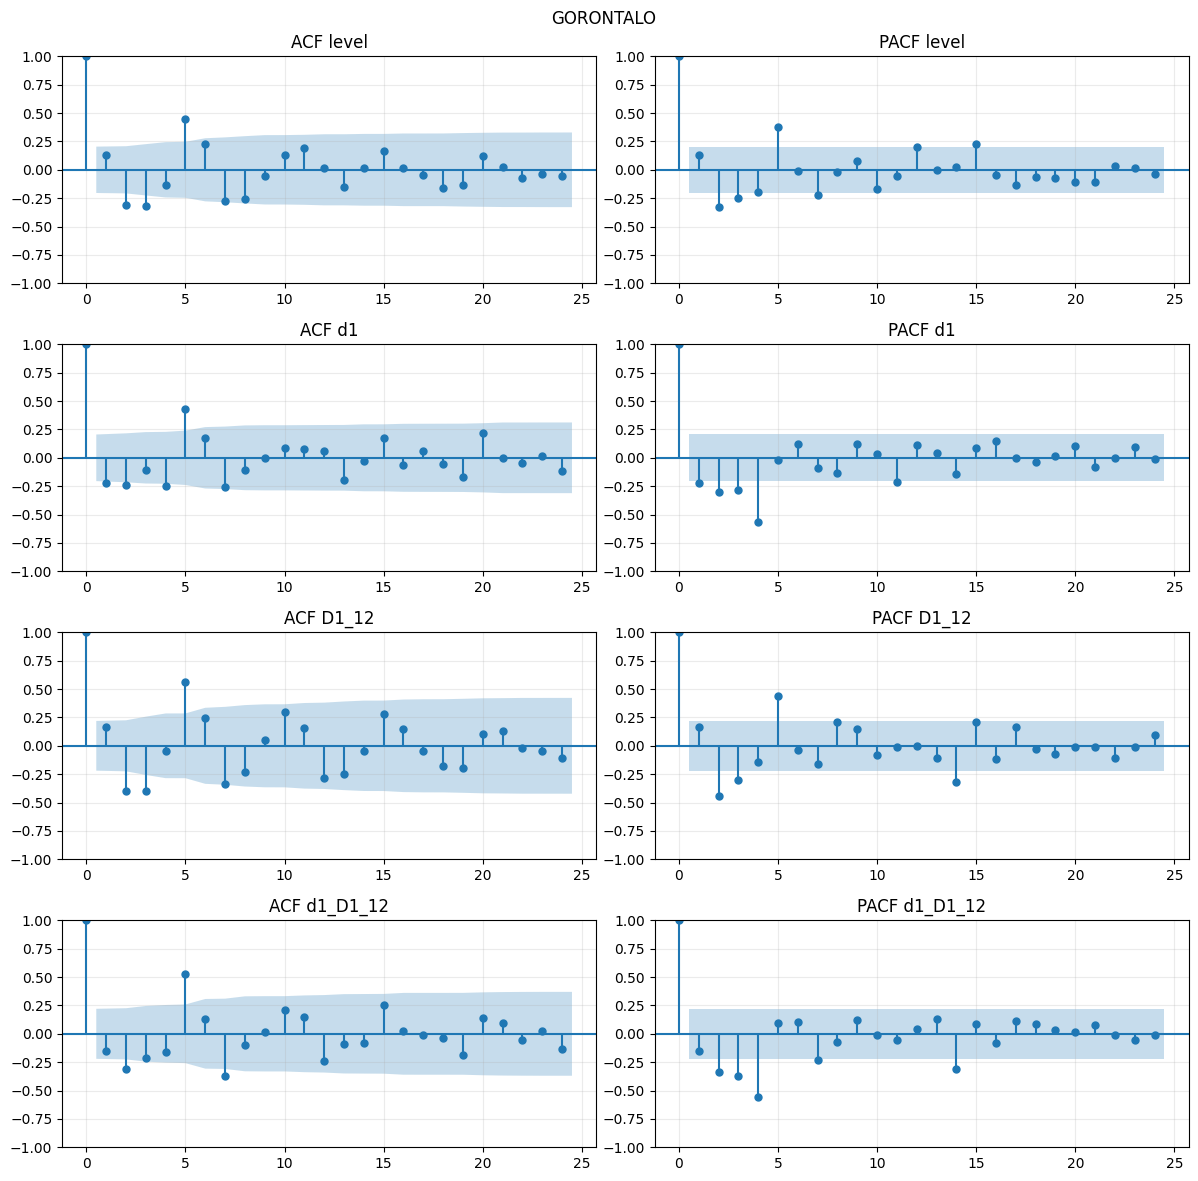

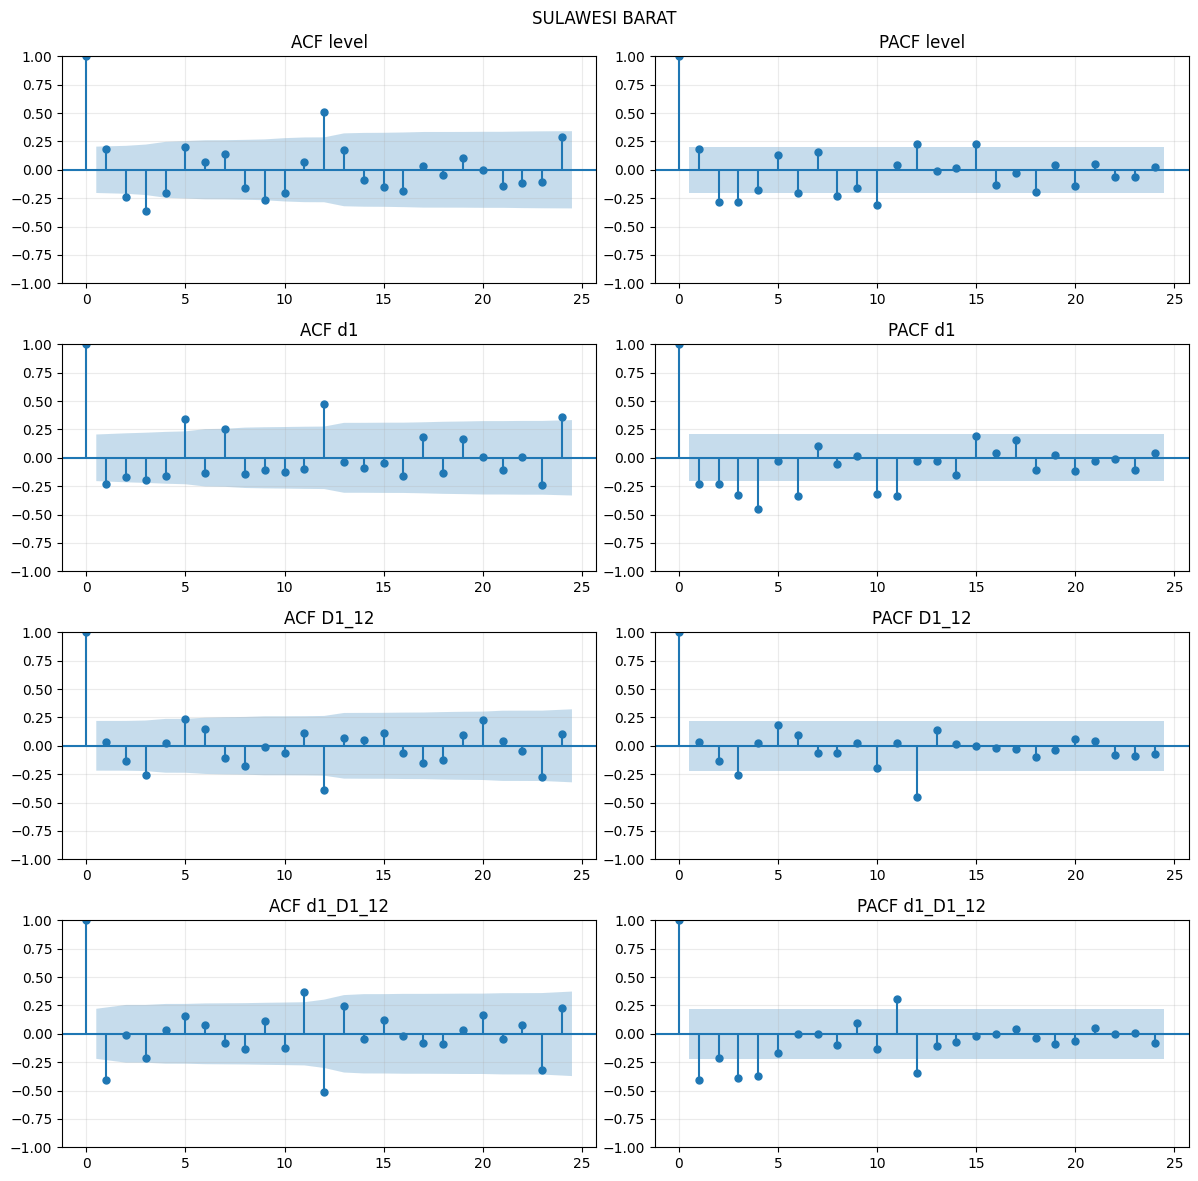

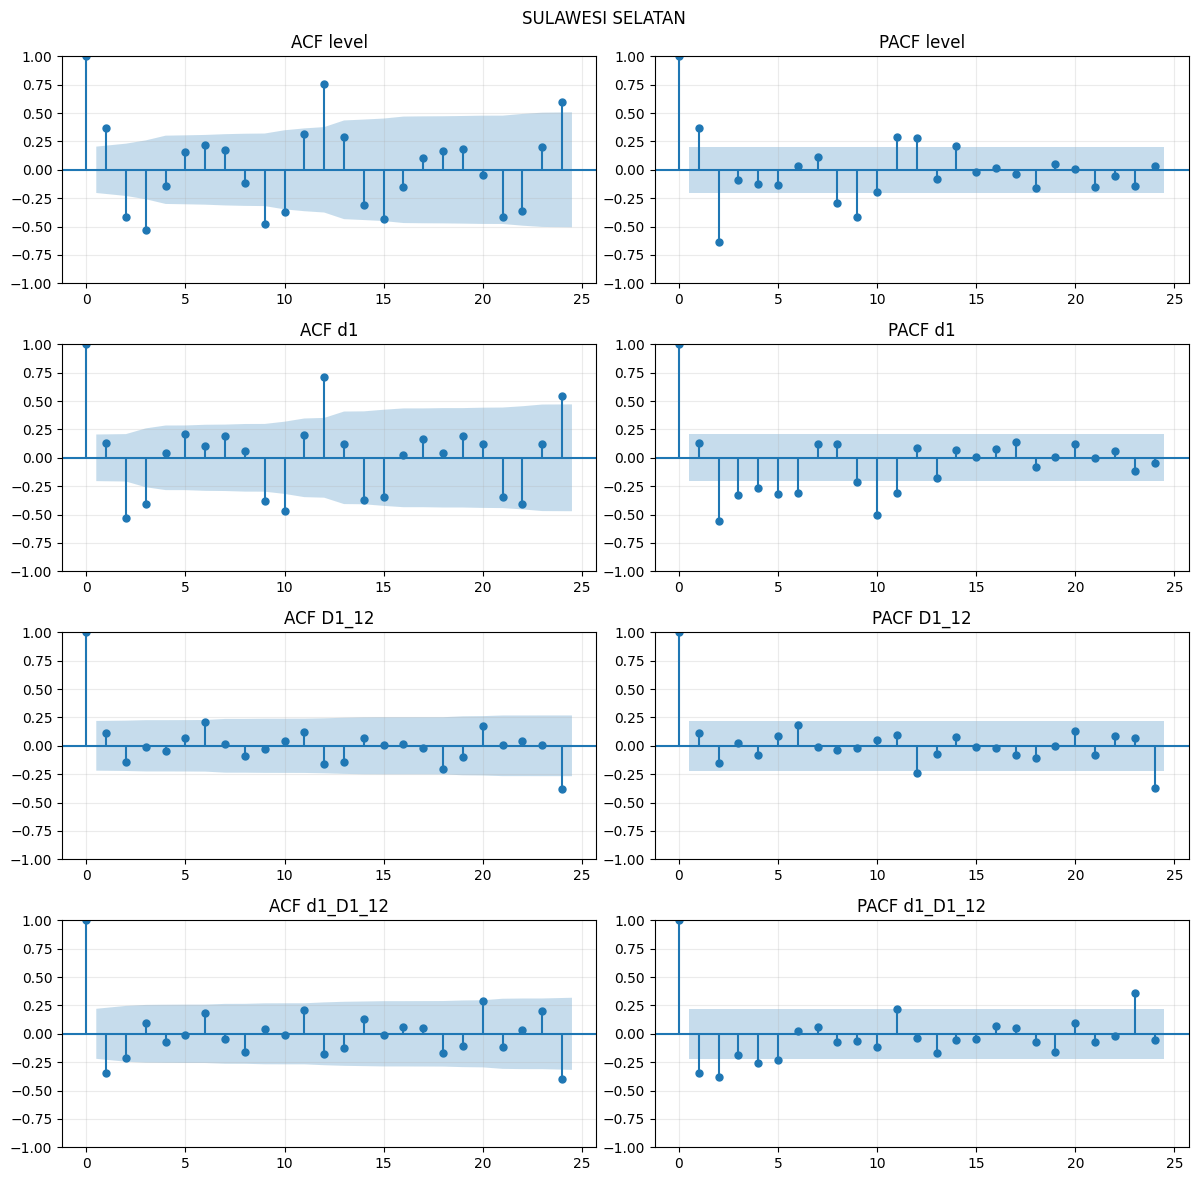

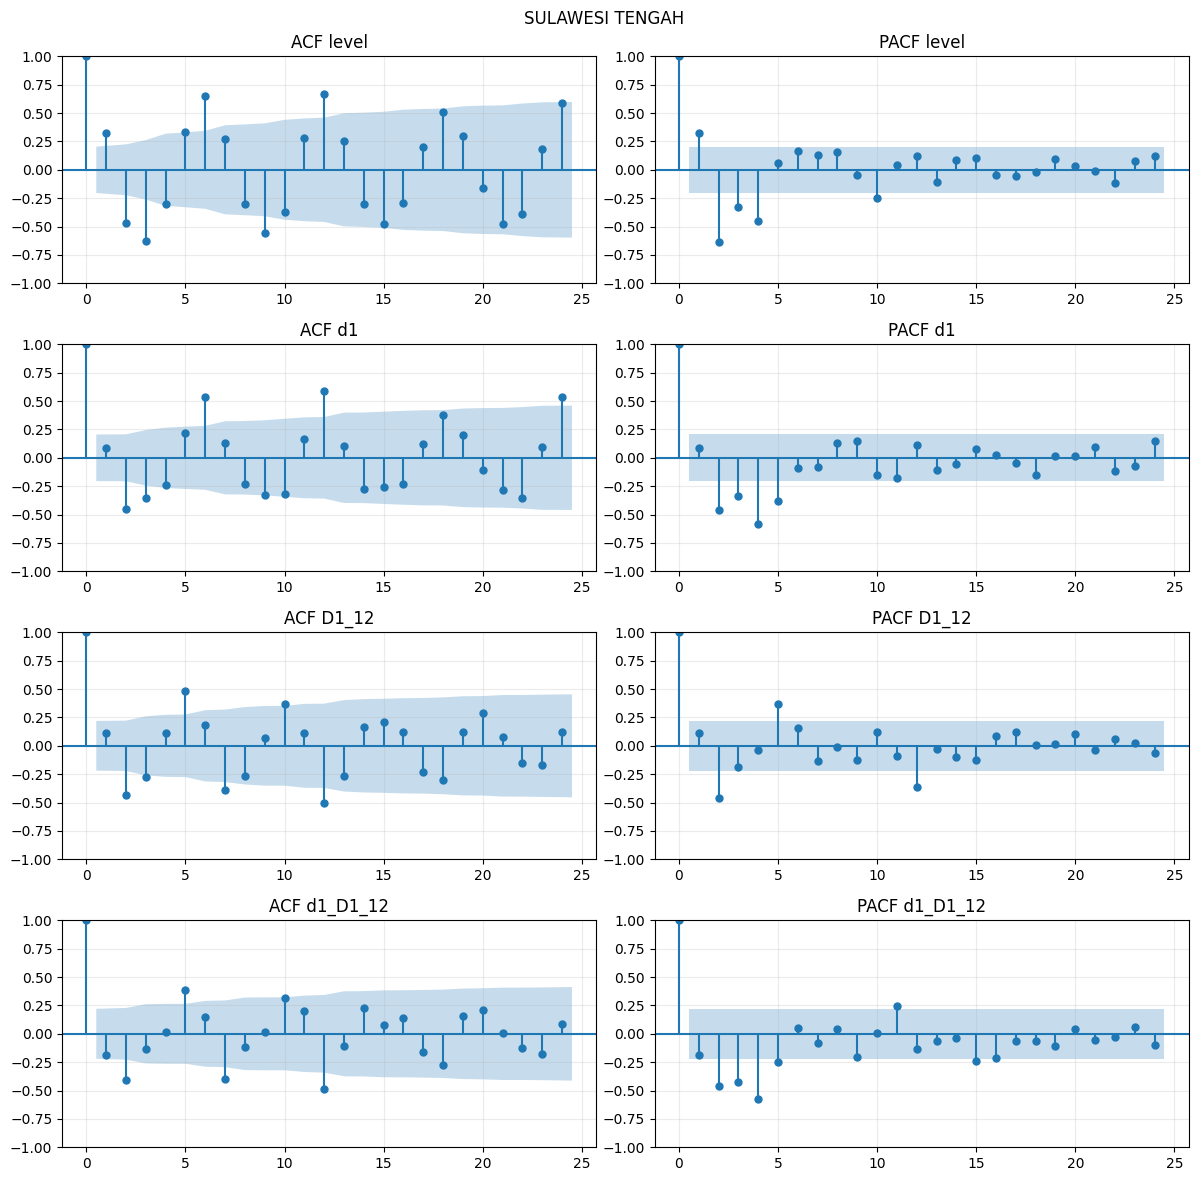

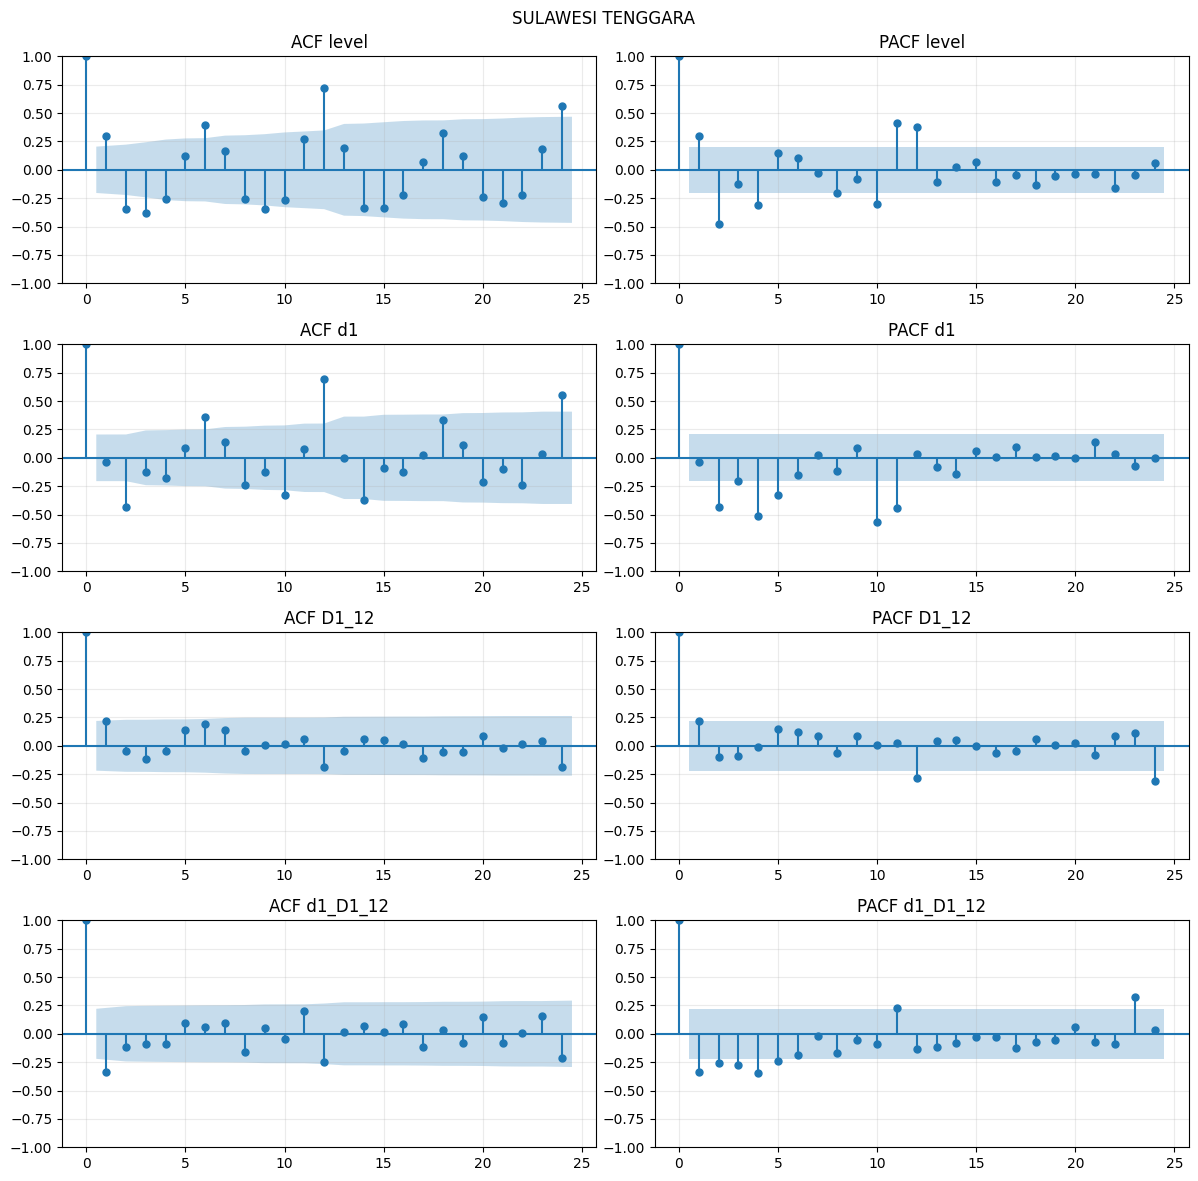

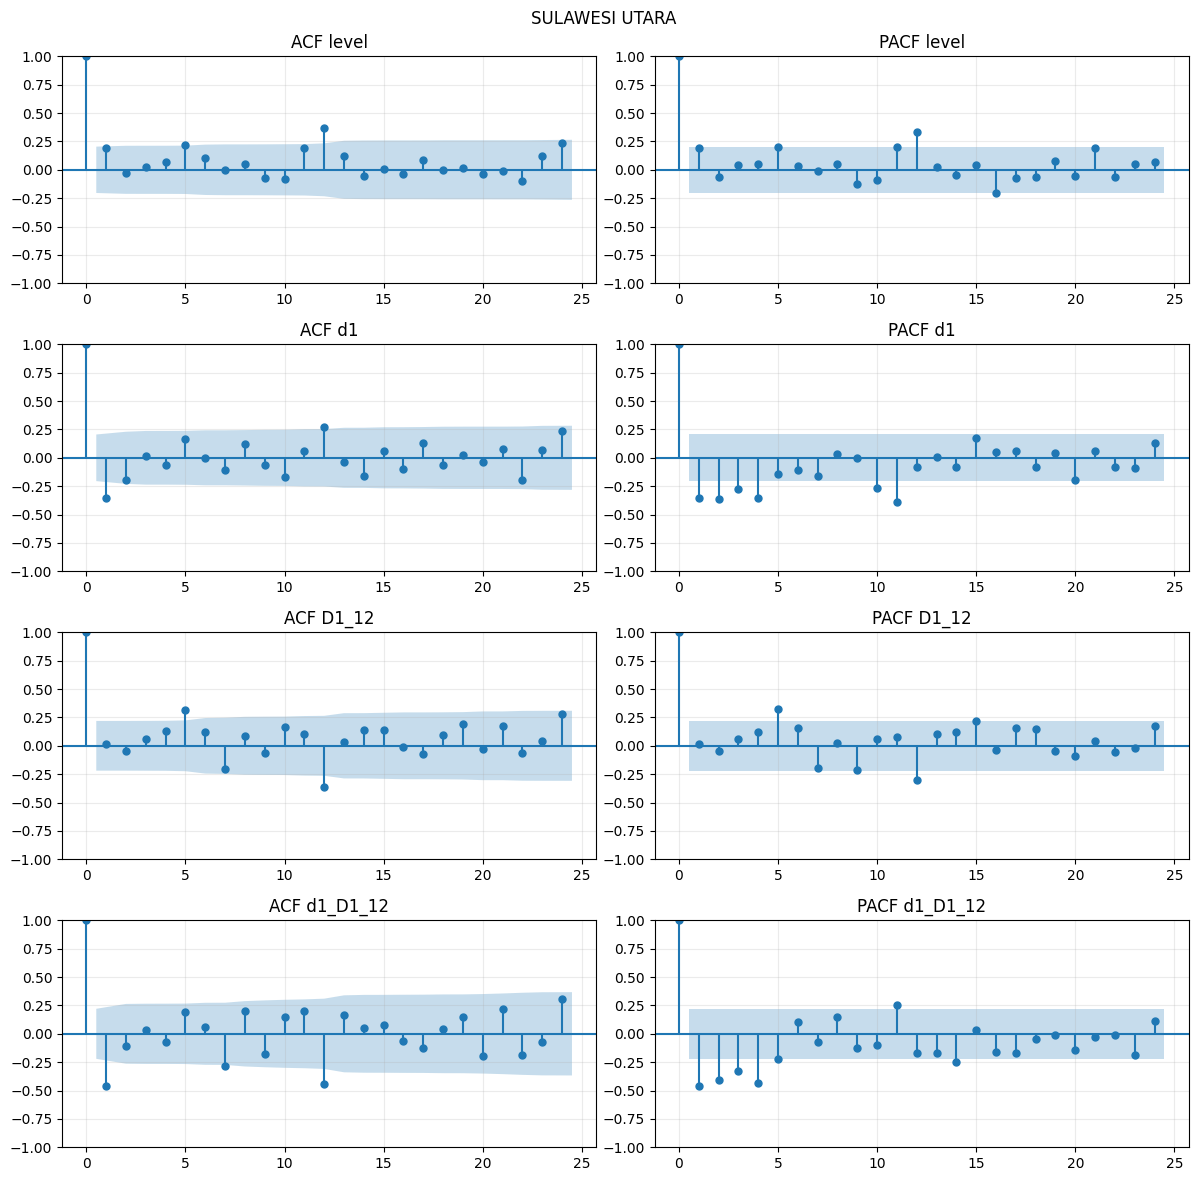

,Provinsi,Variabel,Bentuk,ADF_p,KPSS_p,catatan
0,GORONTALO,Y,level,9.997193e-05,0.100000,The test statistic is outside of the range of ...
1,GORONTALO,Y,log1p,6.102244e-05,0.100000,The test statistic is outside of the range of ...
2,GORONTALO,Y,d1,3.172408e-08,0.077699,
3,GORONTALO,Y,D1_12,3.025174e-01,0.100000,The test statistic is outside of the range of ...
4,GORONTALO,Y,d1_D1_12,3.197479e-08,0.100000,The test statistic is outside of the range of ...
...,...,...,...,...,...,...
85,SULAWESI UTARA,X2,level,3.058578e-03,0.046933,
86,SULAWESI UTARA,X2,log1p,1.393996e-05,0.092272,
87,SULAWESI UTARA,X2,d1,3.548960e-03,0.100000,The test statistic is outside of the range of ...
88,SULAWESI UTARA,X2,D1_12,1.075794e-02,0.100000,The test statistic is outside of the range of ...


In [6]:
def uji_stasioner(s):
    s = pd.Series(s).dropna()
    if len(s)<20 or s.nunique()<3:
        return {'ADF_p':np.nan,'KPSS_p':np.nan,'catatan':'Terlalu pendek/konstan'}
    try:
        with warnings.catch_warnings(record=True) as w:
            warnings.simplefilter('always')
            a = adfuller(s,regression='c',autolag='AIC')
            k = kpss(s,regression='c',nlags='auto')
        return {'ADF_p':a[1],'KPSS_p':k[1],
                'catatan':'; '.join(str(v.message) for v in w)}
    except Exception as e:
        return {'ADF_p':np.nan,'KPSS_p':np.nan,'catatan':str(e)}

st_rows=[]
for p,g in train.items():
    for c in ['Y','X1','X2']:
        s=g[c]
        bentuk={'level':s,'log1p':np.log1p(s),'d1':s.diff(),
                'D1_12':s.diff(S),'d1_D1_12':s.diff(S).diff()}
        for nama,v in bentuk.items():
            st_rows.append({'Provinsi':p,'Variabel':c,'Bentuk':nama,**uji_stasioner(v)})
    fig,axes=plt.subplots(4,2,figsize=(12,12))
    for row,(nama,s) in enumerate({'level':g.Y,'d1':g.Y.diff(),
                                 'D1_12':g.Y.diff(S),'d1_D1_12':g.Y.diff(S).diff()}.items()):
        s=s.dropna(); lags=min(24,len(s)//2-1)
        plot_acf(s,lags=lags,ax=axes[row,0],title=f'ACF {nama}')
        plot_pacf(s,lags=lags,ax=axes[row,1],method='ywm',title=f'PACF {nama}')
    fig.suptitle(p)
    simpan_gambar(f'ACF_PACF_{p}')
stasioner=pd.DataFrame(st_rows)
display(stasioner); simpan_tabel(stasioner,'05_uji_stasioner')

## 4. Modeling
### 4.1 Bentuk model dan rancangan pencarian
SARIMAX ditulis sebagai $Y_t=\beta_1 X_{1t}+\beta_2 X_{2t}+u_t$, dengan $u_t$ mengikuti SARIMA$(p,d,q)(P,D,Q)_{12}$ serta intersep/drift sesuai spesifikasi. SARIMA adalah model tanpa X. Koefisien dilaporkan pada skala yang digunakan untuk estimasi; notebook juga mengonversi koefisien X ke perubahan satuan Y per satu satuan X.

Kandidat terbatas: enam struktur AR/MA, dikombinasikan dengan empat pasangan (d,D), total 24 kandidat per keluarga. Ini pencarian praktis, bukan seluruh kemungkinan orde. Konstanta disertakan ketika d+D ≤ 1, d+D=1 berarti drift dalam proses galat yang diintegrasikan. Model d+D=2 tanpa konstanta. Orde dapat diperluas setelah pemeriksaan train, tanpa menggunakan test untuk tuning.

**Dua jenis prediksi SARIMAX:**
- **Operasional:** X pada validasi/test diramal dari sejarah sebelum origin dengan seasonal naïve. Inilah dasar pemilihan model dan perbandingan utama.
- **Kondisional:** menggunakan X aktual pada test, hanya analisis tambahan seandainya X tersebut diketahui. Hasil ini tidak boleh diklaim sebagai ramalan operasional 12 bulan jika X belum tersedia saat origin.

Pencarian menolak model yang gagal konvergen; peringatan/kegagalan disimpan. Model dengan RMSE validasi terendah dipilih. AIC/BIC dilaporkan untuk informasi pada fit train, tidak digunakan untuk memilih berdasarkan test.

In [7]:
# Enam struktur (p,q,P,Q), masing-masing dengan empat kombinasi d,D.
STRUKTUR = [(0,0,0,0),(1,0,0,0),(0,1,0,0),
            (1,0,1,0),(0,1,0,1),(1,1,0,1)]
SPECS = [((p,d,q),(P,D,Q,S))
         for d,D in product([0,1],repeat=2) for p,q,P,Q in STRUKTUR]

def metrik(actual,pred,history):
    a,b=np.asarray(actual,float),np.asarray(pred,float)
    if not np.isfinite(a).all() or not np.isfinite(b).all():
        raise ValueError('Metrik menerima nilai tidak valid.')
    nz=np.abs(a)>1e-8
    denom=np.mean(np.abs(np.asarray(history)[S:]-np.asarray(history)[:-S]))
    return {'MAE':mean_absolute_error(a,b),'RMSE':np.sqrt(mean_squared_error(a,b)),
            'MAPE_persen':100*np.mean(np.abs((a[nz]-b[nz])/a[nz])) if nz.any() else np.nan,
            'n_MAPE':int(nz.sum()),'R2':r2_score(a,b),
            'MASE':mean_absolute_error(a,b)/denom if denom>0 else np.nan}

def seasonal_naive(history,index):
    # Siklus 12 observasi terakhir; hanya sejarah sebelum origin.
    a=np.asarray(history)[-S:]
    if len(a)!=S: raise ValueError('Butuh minimal 12 bulan sejarah.')
    result=a[np.arange(len(index))%S]
    if isinstance(history,pd.DataFrame):
        return pd.DataFrame(result,index=index,columns=history.columns)
    return pd.Series(result,index=index,name='prediksi')

def fit_model(g,jenis,spec):
    order,seasonal=spec
    ys=float(g.Y.std(ddof=0)); ys=ys if ys>0 else 1.
    xm=g[['X1','X2']].mean()
    xs=g[['X1','X2']].std(ddof=0).replace(0,1.)
    ex=(g[['X1','X2']]-xm)/xs if jenis=='SARIMAX' else None
    trend='c' if order[1]+seasonal[1]<=1 else 'n'
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter('always')
        model=SARIMAX(g.Y/ys,exog=ex,order=order,seasonal_order=seasonal,
                      trend=trend,enforce_stationarity=True,enforce_invertibility=True)
        fit=model.fit(disp=False,maxiter=MAXITER)
        if not fit.mle_retvals.get('converged',False):
            warnings.warn('L-BFGS belum konvergen; mencoba optimasi Powell.')
            fit=model.fit(method='powell',disp=False,maxiter=2*MAXITER)
    if not fit.mle_retvals.get('converged',False):
        raise RuntimeError('Optimasi tidak konvergen')
    if not np.isfinite(fit.params).all(): raise RuntimeError('Parameter tidak finite')
    return {'fit':fit,'ys':ys,'xm':xm,'xs':xs,'jenis':jenis,'spec':spec,
            'warning':'; '.join(sorted(set(str(v.message) for v in w)))}

def predict_model(bundle,index,x=None):
    ex=None
    if bundle['jenis']=='SARIMAX':
        if x is None or not x.index.equals(index):
            raise ValueError('X prediksi harus lengkap dan sejajar tanggal prediksi.')
        ex=(x[['X1','X2']]-bundle['xm'])/bundle['xs']
    fc=bundle['fit'].get_forecast(steps=len(index),exog=ex)
    mean=np.asarray(fc.predicted_mean)*bundle['ys']
    ci=np.asarray(fc.conf_int(alpha=ALPHA))*bundle['ys']
    # Tidak memotong hasil negatif secara diam-diam: tampilkan untuk evaluasi model.
    if not np.isfinite(mean).all() or not np.isfinite(ci).all():
        raise RuntimeError('Prediksi/interval tidak finite')
    return pd.DataFrame({'Prediksi':mean,'Batas_bawah_95':ci[:,0],
                         'Batas_atas_95':ci[:,1]},index=index)

def folds(g):
    for i in range(N_FOLDS):
        cut=len(g)-(N_FOLDS-i)*CV_H
        yield i+1,g.iloc[:cut],g.iloc[cut:cut+CV_H]

### 4.2 Validasi expanding window dan pemilihan orde
Pada tiap origin, statistik penskalaan dan parameter model diestimasi ulang. X validasi tidak dilihat untuk skenario operasional. RMSE gabungan = akar rata-rata kuadrat RMSE fold karena ukuran fold sama. Baseline dievaluasi pada periode yang identik. Jika semua kandidat suatu keluarga gagal, notebook berhenti dan meminta pemeriksaan, bukan diam-diam menganggap hasilnya sah.

In [ ]:
cv_rows, cv_detail, pilihan = [], [], {}
for p,g in train.items():
    print('Memvalidasi:',p,flush=True)
    pilihan[p]={}
    baseline=[]
    for fold,tr,va in folds(g):
        m=metrik(va.Y,seasonal_naive(tr.Y,va.index),tr.Y)
        baseline.append(m['RMSE'])
        cv_detail.append({'Provinsi':p,'Model':'SNAIVE','Spec':'-','Fold':fold,
                          'Train_akhir':tr.index[-1],'Validasi_awal':va.index[0],**m})
    cv_rows.append({'Provinsi':p,'Model':'SNAIVE','Spec':'-',
                    'CV_RMSE':np.sqrt(np.mean(np.square(baseline))),
                    'Status':'OK','Catatan':''})
    for jenis in ['SARIMA','SARIMAX']:
        sukses=[]
        for spec in SPECS:
            rmses=[]; notes=[]
            try:
                for fold,tr,va in folds(g):
                    b=fit_model(tr,jenis,spec)
                    xv=seasonal_naive(tr[['X1','X2']],va.index)
                    pr=predict_model(b,va.index,xv)
                    m=metrik(va.Y,pr.Prediksi,tr.Y); rmses.append(m['RMSE'])
                    notes.append(b['warning'])
                    cv_detail.append({'Provinsi':p,'Model':jenis,'Spec':str(spec),
                                      'Fold':fold,'Train_akhir':tr.index[-1],
                                      'Validasi_awal':va.index[0],**m})
                score=float(np.sqrt(np.mean(np.square(rmses))))
                sukses.append((score,spec))
                status='OK'
            except Exception as e:
                score=np.nan; status='GAGAL'; notes.append(str(e))
            cv_rows.append({'Provinsi':p,'Model':jenis,'Spec':str(spec),
                            'CV_RMSE':score,'Status':status,'Catatan':' | '.join(filter(None,notes))})
        if not sukses:
            raise RuntimeError(f'{p} {jenis}: seluruh kandidat gagal. Periksa log dan data.')
        pilihan[p][jenis]=min(sukses,key=lambda z:z[0])[1]
    simpan_tabel(pd.DataFrame(cv_rows),'06_pencarian_CV')
    simpan_tabel(pd.DataFrame(cv_detail),'07_detail_fold')
cv=pd.DataFrame(cv_rows)
display(cv[cv.Status=='OK'].sort_values(['Provinsi','CV_RMSE']).groupby('Provinsi').head(5))
preferred={p:cv[(cv.Provinsi==p)&(cv.Status=='OK')].sort_values('CV_RMSE').iloc[0].Model
           for p in train}
print('Keluarga terpilih berdasarkan validasi:',preferred)

Memvalidasi: GORONTALO
Memvalidasi: SULAWESI BARAT
Memvalidasi: SULAWESI SELATAN


## 5. Evaluation
### 5.1 Estimasi pada train dan diagnostik residual
Ringkasan parameter, standard error, p-value, dan interval parameter disimpan. Diagnostik memakai innovation terstandar setelah periode awal yang dibuang, bukan error test. Ljung–Box memakai koreksi derajat bebas p+q+P+Q pada lag 12 dan 24. p > 0,05 berarti belum ada bukti autokorelasi pada lag yang diuji, bukan jaminan white noise.

Shapiro–Wilk menilai normalitas; ARCH-LM menilai heteroskedastisitas bersyarat. Normalitas bukan syarat mutlak ramalan titik, tetapi penyimpangan distribusi/varians memengaruhi keandalan interval Gaussian. Penolakan Ljung–Box menjadi catatan bahwa model masih perlu dikembangkan menggunakan train dan validasi. Jangan mengganti model berulang kali untuk mengejar hasil test.

In [ ]:
trained, diag_rows, param_rows = {}, [], []
for p,g in train.items():
    trained[p]={}
    for jenis in ['SARIMA','SARIMAX']:
        spec=pilihan[p][jenis]
        b=fit_model(g,jenis,spec); trained[p][jenis]=b
        res=b['fit']
        (OUT/f'ringkasan_{p}_{jenis}.txt').write_text(res.summary().as_text(),encoding='utf-8')
        print(p,jenis,spec,'AIC=',round(res.aic,2),'BIC=',round(res.bic,2))
        conf=res.conf_int()
        for term in res.params.index:
            param_rows.append({'Provinsi':p,'Model':jenis,'Parameter':term,
                'Koef_skala_model':res.params[term],'SE':res.bse[term],'p_value':res.pvalues[term],
                'CI_bawah':conf.loc[term].iloc[0],'CI_atas':conf.loc[term].iloc[1],
                'Beta_satuan_asli':res.params[term]*b['ys']/b['xs'][term]
                    if term in ['X1','X2'] else np.nan})
        order,seasonal=spec
        burn=max(res.loglikelihood_burn, S+1)
        e=np.asarray(res.filter_results.standardized_forecasts_error[0])[burn:]
        e=e[np.isfinite(e)]
        dof=order[0]+order[2]+seasonal[0]+seasonal[2]
        lags=[k for k in [12,24] if dof<k<len(e)]
        lb=acorr_ljungbox(e,lags=lags,model_df=dof,return_df=True)
        sw=stats.shapiro(e)
        arch=het_arch(e,nlags=min(12,len(e)//5),ddof=dof)
        row={'Provinsi':p,'Model':jenis,'Spec':str(spec),'AIC':res.aic,'BIC':res.bic,
             'n_residual':len(e),'Shapiro_p':sw.pvalue,'ARCH_LM_p':arch[1],
             'Warning_fit':b['warning']}
        for lag in lags: row[f'LjungBox_p_lag{lag}']=lb.loc[lag,'lb_pvalue']
        row['LB_lolos_lag_diuji']=bool((lb.lb_pvalue>ALPHA).all()) if len(lb) else False
        diag_rows.append(row)
        fig,axes=plt.subplots(2,2,figsize=(12,8))
        axes[0,0].plot(e); axes[0,0].axhline(0,color='red'); axes[0,0].set_title('Innovation terstandar')
        axes[0,1].hist(e,bins=15,density=True); axes[0,1].set_title('Histogram residual')
        stats.probplot(e,dist='norm',plot=axes[1,0])
        plot_acf(e,lags=min(24,len(e)//2-1),ax=axes[1,1])
        fig.suptitle(f'{p}: {jenis} {spec}')
        simpan_gambar(f'diagnostik_{p}_{jenis}')
diagnostik=pd.DataFrame(diag_rows)
display(diagnostik); display(pd.DataFrame(param_rows))
simpan_tabel(diagnostik,'08_diagnostik_train')
simpan_tabel(pd.DataFrame(param_rows),'09_parameter_train')

### 5.2 Evaluasi test yang belum digunakan untuk pemilihan
MAE dan RMSE makin kecil makin baik. MAPE tidak dihitung pada Y=0; `n_MAPE` mencatat jumlah titik yang disertakan. R² test dapat negatif. MASE membandingkan error dengan rerata error seasonal naïve di train. Interval SARIMAX bersifat **kondisional pada lintasan X yang dimasukkan** dan belum memasukkan ketidakpastian ramalan X.

Model terpilih tetap berdasarkan CV. Test menunjukkan apakah kinerja tersebut bertahan pada periode lain. Grafik kondisional menggunakan garis putus-putus agar tidak tercampur dengan skenario operasional. Prediksi negatif tidak dipotong otomatis karena pemotongan mengubah estimator dan interval; jika muncul, pertimbangkan model respons positif pada pengembangan berikutnya.

In [ ]:
eval_rows, test_preds = [], []
for p,tr in train.items():
    te=test[p]
    fig,ax=plt.subplots(figsize=(12,5))
    ax.plot(tr.index[-24:],tr.Y.iloc[-24:],color='grey',label='Train (24 bulan terakhir)')
    ax.plot(te.index,te.Y,'ko-',label='Aktual test')
    cases=[('SNAIVE','operasional',pd.DataFrame({'Prediksi':seasonal_naive(tr.Y,te.index)}))]
    for jenis in ['SARIMA','SARIMAX']:
        xop=seasonal_naive(tr[['X1','X2']],te.index)
        cases.append((jenis,'operasional',predict_model(trained[p][jenis],te.index,xop)))
    cases.append(('SARIMAX','kondisional_X_aktual',
                  predict_model(trained[p]['SARIMAX'],te.index,te[['X1','X2']])))
    for jenis,scenario,pr in cases:
        row={'Provinsi':p,'Model':jenis,'Skenario':scenario,
             'Terpilih_CV':jenis==preferred[p] and scenario=='operasional',
             **metrik(te.Y,pr.Prediksi,tr.Y)}
        if 'Batas_bawah_95' in pr:
            row['Coverage_95_test']=np.mean((te.Y>=pr.Batas_bawah_95)&(te.Y<=pr.Batas_atas_95))
            row['Lebar_interval_rata2']=(pr.Batas_atas_95-pr.Batas_bawah_95).mean()
        eval_rows.append(row)
        q=pr.copy(); q['Aktual']=te.Y; q['Tanggal']=q.index
        q['Provinsi']=p; q['Model']=jenis; q['Skenario']=scenario; test_preds.append(q)
        ax.plot(te.index,pr.Prediksi,ls='--' if scenario!='operasional' else '-',
                label=f'{jenis}: {scenario}')
    ax.set_title(f'{p} | pilihan CV: {preferred[p]}'); ax.legend(fontsize=8)
    simpan_gambar(f'test_{p}')
evaluasi=pd.DataFrame(eval_rows)
display(evaluasi)
simpan_tabel(evaluasi,'10_evaluasi_test')
simpan_tabel(pd.concat(test_preds,ignore_index=True),'11_prediksi_test')
# Tidak membandingkan RMSE mentah antarprovinsi sebagai ukuran kesulitan:
# besaran produksi berbeda. Gunakan MASE/MAPE dengan keterbatasannya.

## 6. Forecasting & Monitoring
### 6.1 Refit dan ramalan 12 bulan
Dengan data asli, horizon adalah **September 2026–Agustus 2027**. Ramalan dimulai setelah observasi terakhir, bukan setelah tanggal komputer.

Default X masa depan = nilai bulan yang sama setahun sebelumnya. Ini asumsi baseline, bukan klaim mengetahui cuaca atau luas panen masa depan. Alternatif: unggah CSV skenario/prakiraan X, isi `FUTURE_X_PATH`, lalu jalankan ulang sel berikut. Format: `Provinsi,Tanggal,X1,X2`; `Tanggal` harus tanggal awal bulan (contoh `2026-09-01`); masing-masing provinsi 12 baris. Template otomatis tersedia dalam folder output. Ganti nilai X1/X2 dengan prakiraan yang dapat dipertanggungjawabkan.

SARIMA/SARIMAX mempunyai interval prediksi 95% model. Untuk baseline seasonal naïve, interval ditandai kosong karena notebook tidak mengestimasi distribusi error baseline. Jangan menyebut interval SARIMAX sebagai interval yang sudah mencakup ketidakpastian X. Jika keluarga terpilih baseline, ramalan baseline tetap ditampilkan, tidak dipaksa menjadi SARIMAX.

In [ ]:
template=[]
for p,g in seri.items():
    idx=pd.date_range(g.index[-1]+pd.offsets.MonthBegin(1),periods=H,freq='MS')
    x=seasonal_naive(g[['X1','X2']],idx)
    x['Provinsi']=p; x['Tanggal']=idx; template.append(x)
template=pd.concat(template,ignore_index=True)[['Provinsi','Tanggal','X1','X2']]
simpan_tabel(template,'template_X_masa_depan')
future_x=None
if FUTURE_X_PATH is not None:
    future_x=pd.read_csv(FUTURE_X_PATH,parse_dates=['Tanggal'])
    future_x['Provinsi']=future_x.Provinsi.str.strip().str.upper()
    if future_x.duplicated(['Provinsi','Tanggal']).any():
        raise ValueError('Duplikasi pada skenario X masa depan.')
    for c in ['X1','X2']:
        future_x[c]=pd.to_numeric(future_x[c],errors='raise')
    if future_x[['X1','X2']].isna().any().any() or (future_x[['X1','X2']]<0).any().any():
        raise ValueError('X masa depan kosong atau negatif.')
    if not np.isfinite(future_x[['X1','X2']].to_numpy()).all():
        raise ValueError('X masa depan tidak finite.')

fc_rows, final_models = [], {}
for p,g in seri.items():
    idx=pd.date_range(g.index[-1]+pd.offsets.MonthBegin(1),periods=H,freq='MS')
    if future_x is None:
        x=seasonal_naive(g[['X1','X2']],idx); sumber='seasonal_naive_X'
    else:
        x=future_x.loc[future_x.Provinsi==p].set_index('Tanggal')[['X1','X2']].sort_index()
        if not x.index.equals(idx): raise ValueError(f'{p}: tanggal X harus persis 12 bulan horizon.')
        sumber='skenario_pengguna'
    final_models[p]={}
    for jenis in ['SNAIVE','SARIMA','SARIMAX']:
        if jenis=='SNAIVE':
            pr=pd.DataFrame({'Prediksi':seasonal_naive(g.Y,idx),
                             'Batas_bawah_95':np.nan,'Batas_atas_95':np.nan})
        else:
            b=fit_model(g,jenis,pilihan[p][jenis]); final_models[p][jenis]=b
            pr=predict_model(b,idx,x)
            (OUT/f'ringkasan_final_{p}_{jenis}.txt').write_text(b['fit'].summary().as_text(),encoding='utf-8')
        q=pr.copy(); q['Provinsi']=p; q['Tanggal']=idx; q['Model']=jenis
        q['Terpilih_CV']=jenis==preferred[p]
        q['X1_skenario']=x.X1; q['X2_skenario']=x.X2
        q['Sumber_X']=sumber if jenis=='SARIMAX' else 'tidak_digunakan'
        fc_rows.append(q)
        if jenis==preferred[p]:
            fig,ax=plt.subplots(figsize=(12,5))
            ax.plot(g.index[-36:],g.Y.iloc[-36:],label='Aktual')
            ax.plot(idx,pr.Prediksi,'o-',label=f'Ramalan {jenis}')
            if jenis!='SNAIVE':
                ax.fill_between(idx,pr.Batas_bawah_95,pr.Batas_atas_95,alpha=.2,label='Interval model 95%')
            ax.set_title(f'{p} | {jenis} | 12 bulan'); ax.legend()
            simpan_gambar(f'forecast_terpilih_{p}')
forecast=pd.concat(fc_rows,ignore_index=True)
display(forecast[forecast.Terpilih_CV])
simpan_tabel(forecast,'12_forecast_semua_model')
simpan_tabel(forecast[forecast.Terpilih_CV],'13_forecast_terpilih')
if (forecast.Prediksi<0).any():
    print('PERHATIAN: terdapat ramalan negatif. Tinjau model respons positif sebelum digunakan.')
# Agregat produksi Sulawesi: jumlah titik ramalan model terpilih per provinsi.
# Tidak menjumlahkan batas interval, karena dependensi error antarprovinsi belum dimodelkan.
agregat=forecast[forecast.Terpilih_CV].groupby('Tanggal',as_index=False).Prediksi.sum()
simpan_tabel(agregat,'14_total_produksi_sulawesi_tanpa_interval')

### 6.2 Monitoring setelah aktual baru tersedia
Isi aktual baru dengan kolom `Provinsi,Tanggal,Y`, lalu jalankan fungsi di bawah. Hanya tanggal yang cocok dengan ramalan model terpilih yang dinilai. Simpan ramalan awal sebelum refit agar audit tidak mengganti ramalan lama dengan fitted values baru. Laporkan MAE/RMSE kumulatif, error tiap bulan, dan coverage interval bila tersedia.

Contoh aturan operasional awal: tinjau model jika MAE pada sedikitnya tiga bulan realisasi melebihi 1,5 kali MAE test model yang sama. Ini ambang heuristik, **bukan uji statistik concept drift**. Ketika data baru bertambah, periksa perubahan pola, revisi sumber X, dan lakukan validasi ulang pada jadwal yang ditetapkan, misalnya triwulanan.

In [ ]:
def monitoring(aktual_baru):
    a=aktual_baru.copy()
    a['Tanggal']=pd.to_datetime(a.Tanggal)
    a['Provinsi']=a.Provinsi.str.strip().str.upper()
    a['Y']=pd.to_numeric(a.Y,errors='raise')
    if a.duplicated(['Provinsi','Tanggal']).any(): raise ValueError('Aktual duplikat.')
    if not np.isfinite(a.Y).all() or (a.Y<0).any(): raise ValueError('Aktual Y tidak valid.')
    z=forecast[forecast.Terpilih_CV].merge(a[['Provinsi','Tanggal','Y']],
                                           on=['Provinsi','Tanggal'],how='inner',validate='one_to_one')
    if z.empty: raise ValueError('Belum ada aktual yang cocok dengan periode ramalan.')
    z['Error']=z.Y-z.Prediksi; z['Absolute_error']=z.Error.abs()
    hasil=[]
    for p,g in z.groupby('Provinsi'):
        model=g.Model.iloc[0]
        ref=evaluasi[(evaluasi.Provinsi==p)&(evaluasi.Model==model)&(evaluasi.Skenario=='operasional')].iloc[0]
        mae=g.Absolute_error.mean()
        hasil.append({'Provinsi':p,'Model':model,'n_aktual':len(g),'MAE':mae,
                      'RMSE':np.sqrt(np.mean(g.Error**2)),
                      'Coverage':np.mean((g.Y>=g.Batas_bawah_95)&(g.Y<=g.Batas_atas_95))
                          if g.Batas_bawah_95.notna().all() else np.nan,
                      'Tinjau_model':len(g)>=3 and mae>1.5*ref.MAE})
    hasil=pd.DataFrame(hasil)
    simpan_tabel(z,'15_monitoring_detail'); simpan_tabel(hasil,'16_monitoring_ringkas')
    return hasil

# Contoh, aktifkan setelah file aktual tersedia:
# aktual_baru = pd.read_csv('aktual_padi_baru.csv')
# display(monitoring(aktual_baru))

### 6.3 Ringkasan hasil, catatan interpretasi, dan unduh
Tabel ringkas menggabungkan pilihan CV, akurasi test operasional, dan diagnostik train. Jika diagnostik gagal, statusnya ditampilkan secara terbuka. Model terpilih berarti terbaik di antara kandidat menurut protokol ini, bukan pasti terbaik di seluruh kelas model.

**Untuk penulisan laporan:** jelaskan periode data, split, panjang musim 12, orde terpilih, metode penyediaan X, akurasi test, hasil Ljung–Box, serta keterbatasan interval. Signifikansi X tidak membuktikan pengaruh kausal. Jika menggunakan skenario X dari pengguna, kualitas prakiraan itu belum tercermin dalam skor CV berbasis seasonal naïve.

File CSV dapat dibuka di Excel; gambar PNG dan ringkasan TXT siap digunakan untuk pemeriksaan hasil. File sumber tidak ditimpa. Notebook disediakan tanpa hasil estimasi yang dipalsukan: keluaran lengkap akan muncul saat semua sel dijalankan.

In [ ]:
ringkas=evaluasi[evaluasi.Terpilih_CV].merge(
    diagnostik,on=['Provinsi','Model'],how='left')
display(ringkas)
simpan_tabel(ringkas,'17_ringkasan_model_terpilih')
konfig={'versi':VERSI,'periode_musiman':S,'horizon':H,'test_size':TEST_SIZE,
        'n_folds':N_FOLDS,'cv_horizon':CV_H,'maxiter':MAXITER,
        'kandidat':SPECS,'pilihan_orde':pilihan,'pilihan_model_CV':preferred,
        'future_X':str(FUTURE_X_PATH),
        'catatan':'CV/test operasional menggunakan seasonal naive X; interval kondisional pada X.'}
(OUT/'konfigurasi.json').write_text(json.dumps(konfig,indent=2,default=str),encoding='utf-8')
zip_path=shutil.make_archive(str(OUT),'zip',root_dir=OUT)
print('Hasil tersimpan:',zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print('Di luar Colab: buka file ZIP pada direktori kerja.')

### Referensi implementasi
- Acuan urutan analisis: PDF *Tahapan pemodelan data deret waktu* yang Anda lampirkan.
- Dokumentasi resmi statsmodels 0.14.6: [SARIMAX](https://www.statsmodels.org/v0.14.6/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html).
- Prediksi menggunakan metode `get_forecast`; pemeriksaan autokorelasi menggunakan `acorr_ljungbox`. Alur pemuatan data hingga monitoring diuji pada enam provinsi menggunakan grid kecil untuk pemeriksaan fungsi. Pencarian 24 kandidat per keluarga disiapkan untuk dijalankan penuh di Colab; hasil grid kecil bukan hasil akhir penelitian. Unggah dan unduh interaktif memerlukan Google Colab.